# SIMULACION MONTECARLO DE YAHTZEE
## Actividad didáctica 2-M1
* FASE 1 - USA: mapear el codigo, diagrama de flujo y reporte de convergencia con 10, 1.000 y 100.000 iteraciones (ley de los grandes numeros)
* FASE 2 - MODIFICA: dados cargados (el 6 con 30% de probabilidad) y analisis de su efecto sobre yahtzee
## integrantes:
* ciro antonio carrillo mendoza
*
*
*

# 0. instalacion de dependencias y parametros de operacion

In [2]:
# Depenencias y paramentros de operacion
import os, math, time, bisect, random, itertools
from collections import Counter
from contextlib import contextmanager
from dataclasses import dataclass, field
from typing import List, Dict, Optional, Tuple
# librerias de graficas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
# guardar figuras y tablas
os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)
sns.set_theme(style="whitegrid")
# parametros montecarlo
SIMS_PER_MASK = 300
# semilla
SEED = 42
if SEED is not None:
    random.seed(SEED)

# 1. Motor del juego
## 1.1 modelo del dado

In [3]:
# modelo del dado
CARAS = [1, 2, 3, 4, 5, 6]
PESOS: List[float] = [1/6] * 6      # P(cara) — se reescribe en configurar_dado()
_ACUM: List[float] = []             # probabilidades acumuladas (uso interno)
PROB_SEIS: Optional[float] = None   # None = dado justo; 0.30 = dado cargado

def configurar_dado(prob_seis: Optional[float] = None) -> List[float]:
    global PESOS, _ACUM, PROB_SEIS
    if prob_seis is None:
        PESOS = [1/6] * 6
    else:
        if not (0.0 < prob_seis < 1.0):
            raise ValueError("prob_seis debe estar entre 0 y 1 (exclusivo)")
        resto = (1.0 - prob_seis) / 5.0          # probabilidad de cada cara 1..5
        PESOS = [resto] * 5 + [prob_seis]        # la cara 6 va al final
    # Probabilidad acumulada: [p1, p1+p2, ..., 1.0]
    acumulado, _ACUM = 0.0, []
    for p in PESOS:
        acumulado += p
        _ACUM.append(acumulado)
    _ACUM[-1] = 1.0          # evita que el error de punto flotante deje un hueco
    PROB_SEIS = prob_seis
    return PESOS

@contextmanager
def dado_temporal(prob_seis: Optional[float]):
    anterior = PROB_SEIS
    configurar_dado(prob_seis)
    try:
        yield
    finally:
        configurar_dado(anterior)

configurar_dado(None)   # estado inicial: dado justo (comportamiento del código base)
print("Distribución actual del dado:", [round(p, 4) for p in PESOS])

Distribución actual del dado: [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667]


# 1.2 Utilidades del dado

In [4]:
# utilidades del dado
def roll_single_die() -> int:

    u = random.random()
    return bisect.bisect_right(_ACUM, u) + 1

def roll_dice(values: List[int], locked: List[bool]) -> List[int]:

    nuevos: List[int] = []
    for i, is_locked in enumerate(locked):
        if not is_locked:
            values[i] = roll_single_die()
            nuevos.append(values[i])
    return nuevos

def has_sequence(values: List[int], needed_len: int) -> bool:

    uniq = sorted(set(values))
    if not uniq:
        return False
    longest = curr = 1
    for i in range(1, len(uniq)):
        if uniq[i] == uniq[i-1] + 1:      # consecutivo -> alarga la racha
            curr += 1
            longest = max(longest, curr)
        else:                             # se corta la racha
            curr = 1
    return longest >= needed_len

## 1.3 Reglas de puntuacion

In [5]:
## 1.3 puntuacion
CATEGORIES_ORDER = [
    "ones", "twos", "threes", "fours", "fives", "sixes",
    "threeOfKind", "fourOfKind", "fullHouse", "smallStraight",
    "largeStraight", "yahtzee", "chance"
]

def score_hand(category: str, dice: List[int]) -> int:

    counts = Counter(dice)             # {cara: cuántas veces aparece}
    freqs = list(counts.values())      # sólo las repeticiones, p. ej. [3, 2]
    total = sum(dice)
    if category in ["ones", "twos", "threes", "fours", "fives", "sixes"]:
        num = {"ones": 1, "twos": 2, "threes": 3, "fours": 4, "fives": 5, "sixes": 6}[category]
        return counts.get(num, 0) * num
    if category == "threeOfKind":
        return total if any(f >= 3 for f in freqs) else 0
    if category == "fourOfKind":
        return total if any(f >= 4 for f in freqs) else 0
    if category == "fullHouse":
        return 25 if (2 in freqs and 3 in freqs) else 0
    if category == "smallStraight":
        return 30 if has_sequence(dice, 4) else 0
    if category == "largeStraight":
        return 40 if has_sequence(dice, 5) else 0
    if category == "yahtzee":
        return 50 if 5 in freqs else 0
    if category == "chance":
        return total
    return 0

def best_category_score(dice: List[int], available: List[str]) -> Tuple[str, int]:

    best_cat, best = None, -1
    for cat in available:
        sc = score_hand(cat, dice)
        if sc > best:
            best, best_cat = sc, cat
    return best_cat, best

## 1.4 Estructuras de datos del juego

In [6]:
# 1.4 Estructuras de datos
@dataclass
class PlayerState:

    name: str
    scores: Dict[str, Optional[int]] = field(default_factory=lambda: {c: None for c in CATEGORIES_ORDER})
    total: int = 0

    def available_categories(self) -> List[str]:
        """Categorías todavía sin usar (valor None)."""
        return [c for c, v in self.scores.items() if v is None]

    def set_score(self, category: str, points: int) -> None:
        """Anota puntos en una categoría y recalcula el total."""
        self.scores[category] = points
        self.total = sum(v for v in self.scores.values() if v is not None)

@dataclass
class GameStats:

    total_rolls: int = 0
    face_hist: Counter = field(default_factory=Counter)
    turnos_con_yahtzee: int = 0

    def update_from_roll(self, lanzados: List[int]) -> None:
        # [CORRECCIÓN] recibe SOLO los dados lanzados (no los bloqueados).
        self.total_rolls += len(lanzados)
        self.face_hist.update(lanzados)

@dataclass
class GameState:

    players: List[PlayerState]
    current_player_idx: int = 0
    turn_in_round: int = 0
    dice_values: List[int] = field(default_factory=lambda: [0] * 5)
    locked: List[bool] = field(default_factory=lambda: [False] * 5)
    rolls_left: int = 3
    stats: GameStats = field(default_factory=GameStats)

    def reset_turn(self):
        """Prepara un turno nuevo: dados en 0, nada bloqueado, 3 tiradas."""
        self.dice_values = [0] * 5
        self.locked = [False] * 5
        self.rolls_left = 3

    @property
    def current_player(self) -> PlayerState:
        return self.players[self.current_player_idx]

    def advance_player(self):
        """Pasa al siguiente jugador (circular: 0,1,0,1,...)."""
        self.current_player_idx = (self.current_player_idx + 1) % len(self.players)
        if self.current_player_idx == 0:
            self.turn_in_round += 1

## 1.5 Montecarlo para decidir que dado conservar
Esta es la parte más importante de la Fase 1. La IA usa **simulación Montecarlo** para elegir entre las
**32 máscaras de bloqueo** posibles (2⁵ combinaciones de conservar/relanzar cada dado):

1. Para cada máscara, simula `N` veces qué pasaría si conserva esos dados y relanza el resto.
2. Promedia los puntos obtenidos → **valor esperado estimado (EV)**.
3. Elige la máscara con mayor EV.

In [7]:
# 1.5 Montecarlo para recidir bloqueos

def all_keep_masks() -> List[List[bool]]:

    masks = []
    for m in range(32):
        masks.append([(m >> i) & 1 == 1 for i in range(5)])
    return masks

MASCARAS = all_keep_masks()   # [APORTE] se calcula una sola vez (antes, en cada decisión)

def simulate_expected_value_after_keeps(
    current_values: List[int],
    keep_mask: List[bool],
    rolls_remaining: int,
    available_categories: List[str],
    sims: int
) -> float:

    if rolls_remaining <= 0:
        # Sin tiradas: no hay azar, el "valor esperado" es el puntaje actual.
        _, sc = best_category_score(current_values, available_categories)
        return float(sc)

    kept = [v if keep_mask[i] else None for i, v in enumerate(current_values)]
    unlocked_idx = [i for i, b in enumerate(keep_mask) if not b]

    total_score = 0.0
    for _ in range(sims):                       # <- bucle Montecarlo (N iteraciones)
        vals = kept[:]                          # copia: los conservados se mantienen
        temp = current_values[:]
        for _r in range(rolls_remaining):       # relanza lo no conservado
            for i in unlocked_idx:
                temp[i] = roll_single_die()     # <- aquí entra el PRNG / dado cargado
        for i in range(5):                      # arma la mano final
            vals[i] = vals[i] if vals[i] is not None else temp[i]
        _, sc = best_category_score(vals, available_categories)   # función de respuesta
        total_score += sc                       # acumula
    return total_score / sims if sims > 0 else 0.0     # promedio = EV estimado

def choose_keep_mask_montecarlo(
    current_values: List[int],
    rolls_remaining: int,
    available_categories: List[str],
    sims_per_mask: Optional[int] = None
) -> List[bool]:

    if sims_per_mask is None:
        sims_per_mask = SIMS_PER_MASK
    best_mask, best_ev = None, -1.0
    for mask in MASCARAS:
        ev = simulate_expected_value_after_keeps(
            current_values, mask, rolls_remaining, available_categories, sims_per_mask)
        if ev > best_ev:
            best_ev, best_mask = ev, mask
    return best_mask

## 1.6 Flujo del juego

In [8]:
# flujo del juego
def play_one_turn(state: GameState, verbose: bool = True,
                  sims_per_mask: Optional[int] = None):

    player = state.current_player
    state.reset_turn()

    # --- Tirada inicial (todos los dados libres) ---
    state.stats.update_from_roll(roll_dice(state.dice_values, state.locked))
    state.rolls_left -= 1
    if verbose:
        print(f"\n{player.name} — Tirada 1:", state.dice_values)

    # --- Hasta 2 relanzamientos con decisión Montecarlo ---
    while state.rolls_left > 0:
        keep_mask = choose_keep_mask_montecarlo(
            state.dice_values, state.rolls_left, player.available_categories(), sims_per_mask)
        if all(keep_mask):                       # conservar los 5 = plantarse
            if verbose:
                print(f"{player.name} decide plantarse con:", state.dice_values)
            break
        state.locked = keep_mask[:]
        state.stats.update_from_roll(roll_dice(state.dice_values, state.locked))
        state.rolls_left -= 1
        if verbose:
            print(f"{player.name} — Tirada {3 - state.rolls_left}:", state.dice_values, "| keep:", keep_mask)

    # --- Anotar ---
    cat, sc = best_category_score(state.dice_values, player.available_categories())
    player.set_score(cat, sc)
    if len(set(state.dice_values)) == 1:         # [APORTE] ¿terminó en Yahtzee?
        state.stats.turnos_con_yahtzee += 1
    if verbose:
        print(f"→ {player.name} elige '{cat}' y anota {sc} puntos. Total = {player.total}")
    return state.dice_values[:], cat, sc

def play_game(verbose_each_turn: bool = False, sims_per_mask: Optional[int] = None,
              silencioso: bool = False) -> GameState:

    players = [PlayerState("Jugador 1"), PlayerState("Jugador 2")]
    state = GameState(players=players)
    total_rounds = 13
    if not silencioso:
        print("Iniciando simulación de Montecarlo (motor de IA tomando decisiones)...")
    for _r in range(total_rounds):
        for _p in range(len(players)):
            play_one_turn(state, verbose=verbose_each_turn, sims_per_mask=sims_per_mask)
            state.advance_player()               # imprescindible: pasa el turno
    if not silencioso:
        print("Simulación completada.\n")
    return state

def print_scoreboard(state: GameState):
    """Imprime el marcador final de cada jugador y el ganador."""
    print("\n===== MARCADOR FINAL =====")
    for p in state.players:
        print(f"\n{p.name}: {p.total} puntos")
        for cat in CATEGORIES_ORDER:
            v = p.scores[cat]
            print(f"  - {cat:13s}: {v if v is not None else 0}")
    a, b = state.players
    ganador = a.name if a.total > b.total else (b.name if b.total > a.total else "Empate")
    print(f"\nGanador: {ganador}")

def print_stats(state: GameState):
    """Frecuencia observada de cada cara frente al valor teórico del dado actual."""
    print("\n===== ESTADÍSTICAS =====")
    print(f"Dados individuales lanzados: {state.stats.total_rolls}")
    total = sum(state.stats.face_hist.values())
    for cara in CARAS:
        c = state.stats.face_hist.get(cara, 0)
        print(f" Cara {cara}: {c:5d} veces ({100*c/total:5.2f}%)   teórico: {100*PESOS[cara-1]:5.2f}%")

# FASE 1 - USA (analisis)
## 2.1 Ejecutar el programa base y observar resultados

In [9]:
# corre una partida completa mostrando cada tirada.
random.seed(SEED)
state = play_game(verbose_each_turn=True, sims_per_mask=300)
print_scoreboard(state)
print_stats(state)

Iniciando simulación de Montecarlo (motor de IA tomando decisiones)...

Jugador 1 — Tirada 1: [4, 1, 2, 2, 5]
Jugador 1 — Tirada 2: [4, 5, 2, 6, 5] | keep: [True, False, True, False, True]
Jugador 1 — Tirada 3: [4, 1, 4, 6, 5] | keep: [True, False, False, True, True]
→ Jugador 1 elige 'chance' y anota 20 puntos. Total = 20

Jugador 2 — Tirada 1: [2, 5, 3, 3, 1]
Jugador 2 — Tirada 2: [2, 5, 3, 3, 1] | keep: [True, True, False, True, False]
Jugador 2 — Tirada 3: [3, 5, 3, 4, 5] | keep: [False, True, True, False, False]
→ Jugador 2 elige 'chance' y anota 20 puntos. Total = 20

Jugador 1 — Tirada 1: [6, 3, 4, 1, 2]
Jugador 1 — Tirada 2: [6, 3, 4, 1, 2] | keep: [False, True, True, True, True]
Jugador 1 — Tirada 3: [2, 3, 4, 1, 2] | keep: [False, True, True, True, True]
→ Jugador 1 elige 'smallStraight' y anota 30 puntos. Total = 50

Jugador 2 — Tirada 1: [2, 3, 1, 4, 4]
Jugador 2 — Tirada 2: [2, 3, 1, 4, 4] | keep: [True, True, True, False, True]
Jugador 2 — Tirada 3: [2, 3, 1, 1, 4] | keep

## 2.2 Diagrama: Flujo del turno y ciclo Montecarlo

Diagramas guardados en figuras/diagrama_flujo_yahtzee.png y figuras/ciclo_montecarlo.png


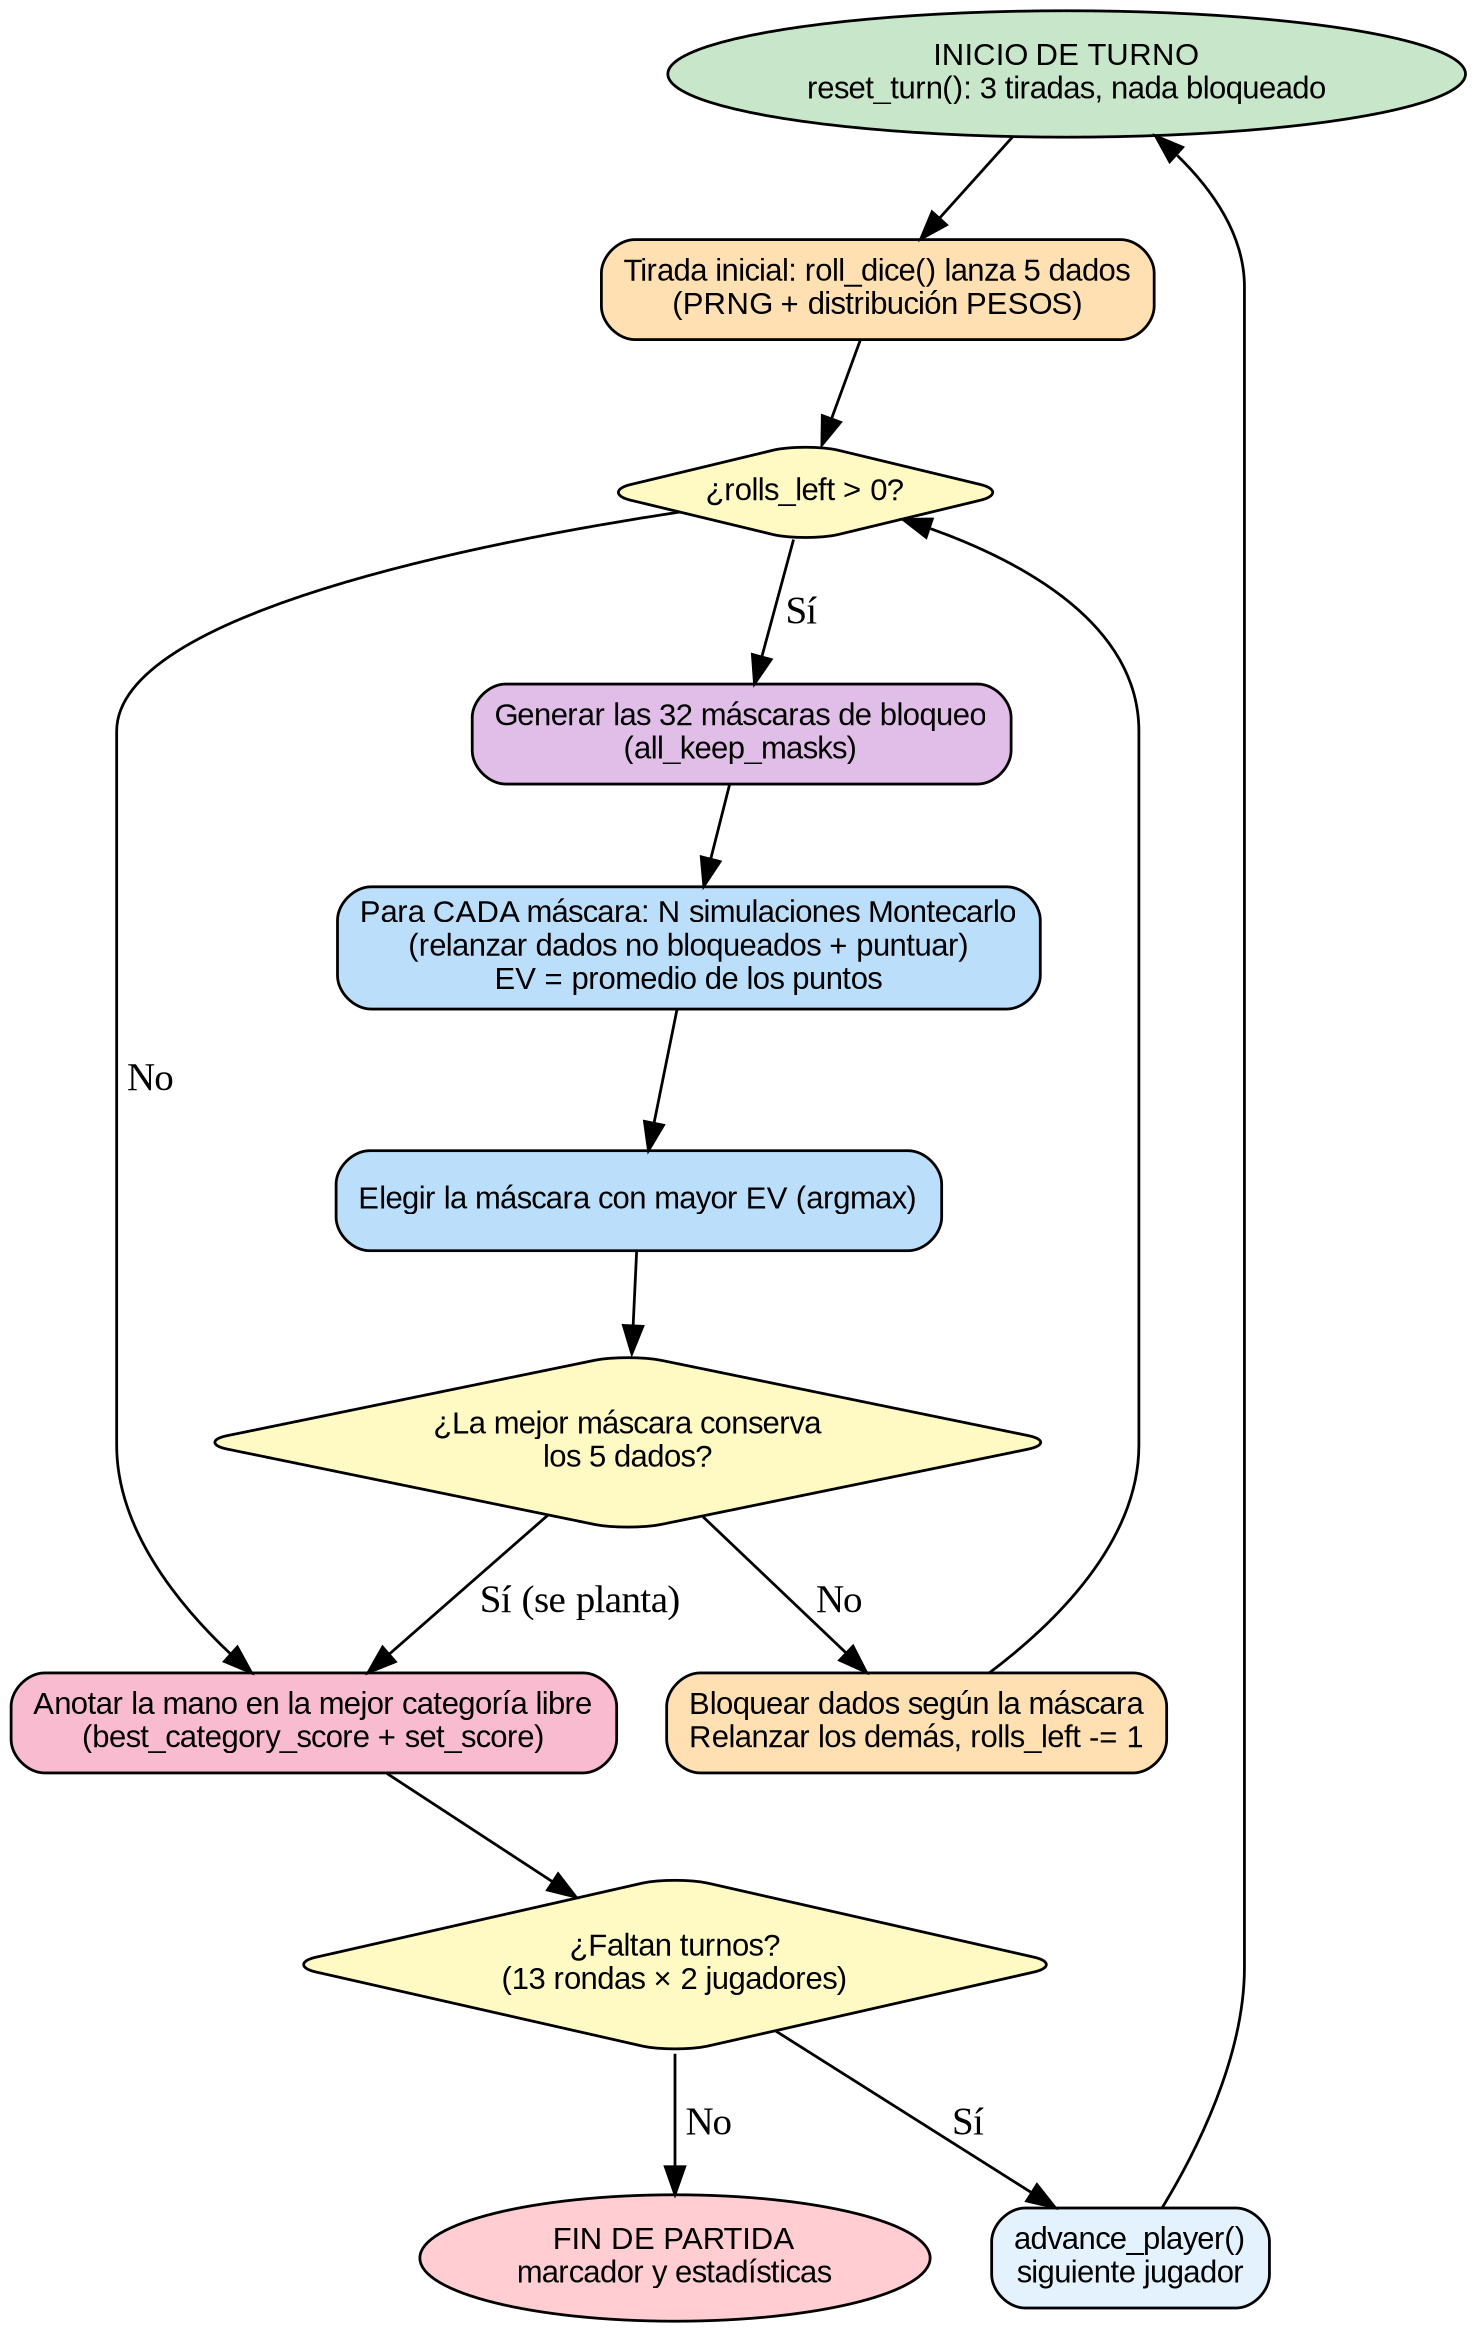

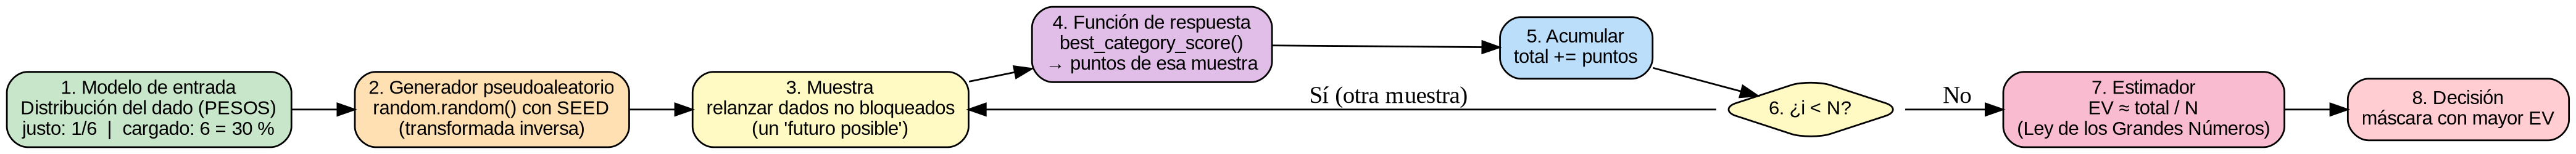

In [10]:
# Diagrama de flujo del turno y ciclo
from graphviz import Digraph

def generar_diagrama_flujo():

    d = Digraph("flujo", format="png")
    d.attr(rankdir="TB", dpi="200", fontname="Arial")
    d.attr("node", shape="box", style="filled,rounded", fontname="Arial", fontsize="11", fillcolor="#E3F2FD")
    d.node("ini", "INICIO DE TURNO\nreset_turn(): 3 tiradas, nada bloqueado", shape="ellipse", fillcolor="#C8E6C9")
    d.node("t1", "Tirada inicial: roll_dice() lanza 5 dados\n(PRNG + distribución PESOS)", fillcolor="#FFE0B2")
    d.node("q1", "¿rolls_left > 0?", shape="diamond", fillcolor="#FFF9C4")
    d.node("m32", "Generar las 32 máscaras de bloqueo\n(all_keep_masks)", fillcolor="#E1BEE7")
    d.node("mc", "Para CADA máscara: N simulaciones Montecarlo\n(relanzar dados no bloqueados + puntuar)\nEV = promedio de los puntos", fillcolor="#BBDEFB")
    d.node("arg", "Elegir la máscara con mayor EV (argmax)", fillcolor="#BBDEFB")
    d.node("q2", "¿La mejor máscara conserva\nlos 5 dados?", shape="diamond", fillcolor="#FFF9C4")
    d.node("rr", "Bloquear dados según la máscara\nRelanzar los demás, rolls_left -= 1", fillcolor="#FFE0B2")
    d.node("an", "Anotar la mano en la mejor categoría libre\n(best_category_score + set_score)", fillcolor="#F8BBD0")
    d.node("q3", "¿Faltan turnos?\n(13 rondas × 2 jugadores)", shape="diamond", fillcolor="#FFF9C4")
    d.node("sig", "advance_player()\nsiguiente jugador", fillcolor="#E3F2FD")
    d.node("fin", "FIN DE PARTIDA\nmarcador y estadísticas", shape="ellipse", fillcolor="#FFCDD2")
    d.edge("ini", "t1"); d.edge("t1", "q1")
    d.edge("q1", "m32", label=" Sí")
    d.edge("q1", "an", label=" No")
    d.edge("m32", "mc"); d.edge("mc", "arg"); d.edge("arg", "q2")
    d.edge("q2", "an", label=" Sí (se planta)")
    d.edge("q2", "rr", label=" No")
    d.edge("rr", "q1")
    d.edge("an", "q3")
    d.edge("q3", "sig", label=" Sí"); d.edge("sig", "ini")
    d.edge("q3", "fin", label=" No")
    return d

def generar_diagrama_ciclo_montecarlo():
    """Diagrama genérico del método Montecarlo aplicado a la decisión de la IA."""
    d = Digraph("ciclo", format="png")
    d.attr(rankdir="LR", dpi="200", fontname="Arial")
    d.attr("node", shape="box", style="filled,rounded", fontname="Arial", fontsize="11", fillcolor="#E3F2FD")
    d.node("a", "1. Modelo de entrada\nDistribución del dado (PESOS)\njusto: 1/6  |  cargado: 6 = 30 %", fillcolor="#C8E6C9")
    d.node("b", "2. Generador pseudoaleatorio\nrandom.random() con SEED\n(transformada inversa)", fillcolor="#FFE0B2")
    d.node("c", "3. Muestra\nrelanzar dados no bloqueados\n(un 'futuro posible')", fillcolor="#FFF9C4")
    d.node("e", "4. Función de respuesta\nbest_category_score()\n→ puntos de esa muestra", fillcolor="#E1BEE7")
    d.node("f", "5. Acumular\ntotal += puntos", fillcolor="#BBDEFB")
    d.node("g", "6. ¿i < N?", shape="diamond", fillcolor="#FFF9C4")
    d.node("h", "7. Estimador\nEV ≈ total / N\n(Ley de los Grandes Números)", fillcolor="#F8BBD0")
    d.node("i", "8. Decisión\nmáscara con mayor EV", fillcolor="#FFCDD2")
    d.edge("a", "b"); d.edge("b", "c"); d.edge("c", "e"); d.edge("e", "f"); d.edge("f", "g")
    d.edge("g", "c", label=" Sí (otra muestra)")
    d.edge("g", "h", label=" No"); d.edge("h", "i")
    return d

generar_diagrama_flujo().render("figuras/diagrama_flujo_yahtzee", cleanup=True)
generar_diagrama_ciclo_montecarlo().render("figuras/ciclo_montecarlo", cleanup=True)
print("Diagramas guardados en figuras/diagrama_flujo_yahtzee.png y figuras/ciclo_montecarlo.png")

from IPython.display import Image
display(Image("figuras/diagrama_flujo_yahtzee.png", width=520))
display(Image("figuras/ciclo_montecarlo.png", width=900))

## 2.3 Reporte de convergencia

Para que el reporte sea sólido se mide la convergencia de **dos cantidades distintas**, siempre con
N = 10, 1.000 y 100.000 (más puntos intermedios para dibujar la curva). Se compara cada estimación con un
**valor exacto calculado analíticamente**, no con la última estimación (el original usaba "el último valor"
como referencia, lo cual es un razonamiento circular).

| Experimento | Qué converge | Valor exacto de referencia |
|---|---|---|
| A | Frecuencia de cada cara de un dado | 1/6 = 16,67 % |
| B | Probabilidad de Yahtzee en **una** tirada de 5 dados | 6·(1/6)⁵ = 1/1296 ≈ 0,0772 % |

TABLA REQUERIDA (N = 10, 1.000 y 100.000). Valor teórico de cada cara: 0,1667


,N,cara 1,cara 2,cara 3,cara 4,cara 5,cara 6,error máx,1/√N (ref.)
0,10,0.3000,0.2000,0.1000,0.1000,0.2000,0.1000,0.1333,0.3162
4,"1,000",0.1650,0.1530,0.1680,0.1790,0.1850,0.1500,0.0183,0.0316
8,"100,000",0.1678,0.1659,0.1660,0.1666,0.1677,0.1660,0.0011,0.0032


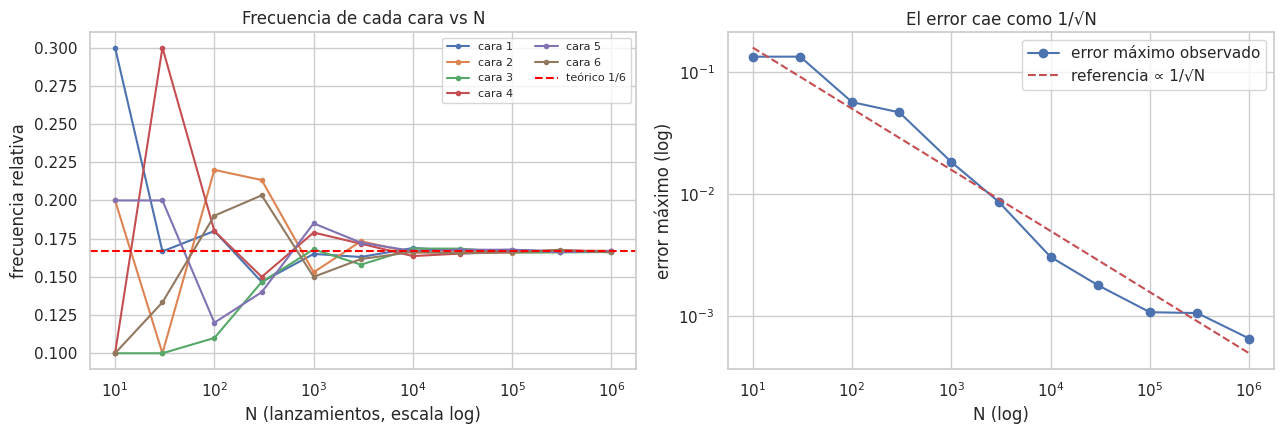

In [12]:
# convergencia de la frecuencia de las caras
NS_REQUERIDOS = [10, 1_000, 100_000] # exigidos por la actividad
NS_CURVA = [10, 30, 100, 300, 1_000, 3_000, 10_000, 30_000, 100_000, 300_000, 1_000_000]

def experimento_caras(ns: List[int]) -> pd.DataFrame:

    filas = []
    for n in ns:
        c = Counter(roll_single_die() for _ in range(n))
        freqs = [c.get(cara, 0) / n for cara in CARAS]
        err = max(abs(f - PESOS[i]) for i, f in enumerate(freqs))
        fila = {"N": n}
        fila.update({f"cara {cara}": f for cara, f in zip(CARAS, freqs)})
        fila["error máx"] = err
        fila["1/√N (ref.)"] = 1 / math.sqrt(n)
        filas.append(fila)
    return pd.DataFrame(filas)

random.seed(SEED)
df_caras = experimento_caras(NS_CURVA)
df_caras.to_csv("resultados/f1_convergencia_caras.csv", index=False)
print("TABLA REQUERIDA (N = 10, 1.000 y 100.000). Valor teórico de cada cara: 0,1667")
display(df_caras[df_caras["N"].isin(NS_REQUERIDOS)].style.format(
    {**{f"cara {c}": "{:.4f}" for c in CARAS}, "error máx": "{:.4f}", "1/√N (ref.)": "{:.4f}", "N": "{:,.0f}"}))
print()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for cara in CARAS:
    ax[0].plot(df_caras["N"], df_caras[f"cara {cara}"], marker="o", ms=3, label=f"cara {cara}")
ax[0].axhline(1/6, color="red", ls="--", label="teórico 1/6")
ax[0].set_xscale("log"); ax[0].set_xlabel("N (lanzamientos, escala log)")
ax[0].set_ylabel("frecuencia relativa"); ax[0].set_title("Frecuencia de cada cara vs N")
ax[0].legend(ncol=2, fontsize=8)
ax[1].loglog(df_caras["N"], df_caras["error máx"], "o-", label="error máximo observado")
ax[1].loglog(df_caras["N"], 1/np.sqrt(df_caras["N"]) * 0.5, "r--", label="referencia ∝ 1/√N")
ax[1].set_xlabel("N (log)"); ax[1].set_ylabel("error máximo (log)")
ax[1].set_title("El error cae como 1/√N"); ax[1].legend()
plt.tight_layout(); plt.savefig("figuras/f1_convergencia_caras.png", dpi=150); plt.show()

Probabilidad exacta (dado justo) = 0.000772  (= 1/1296 = 0.000772)


,N,estimado,exacto,error absoluto,error relativo %
0,10,0.000000,0.000772,0.000772,100.0
1,100,0.010000,0.000772,0.009228,1196.0
2,"1,000",0.002000,0.000772,0.001228,159.2
3,"10,000",0.000700,0.000772,0.000072,9.3
4,"100,000",0.000710,0.000772,0.000062,8.0
5,"1,000,000",0.000815,0.000772,0.000043,5.6


Lectura: con N=10 casi seguro sale 0 (no se ve ningún Yahtzee); recién con N grande el
estimador se acerca. Eventos RAROS necesitan MUCHAS más iteraciones.



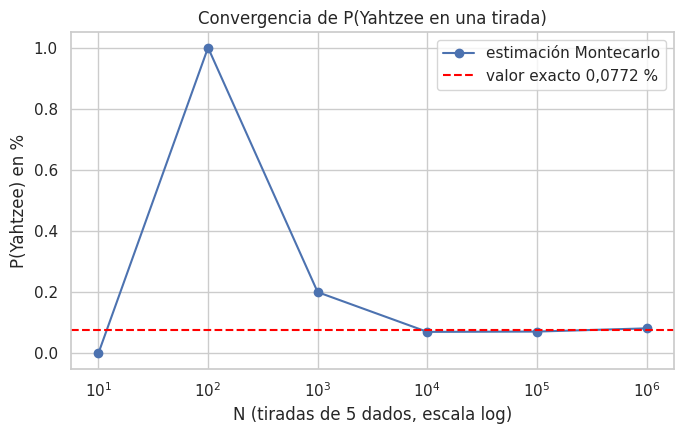

In [14]:
# cnvergencia de p(Yahtzee een una tirada)
def prob_yahtzee_una_tirada_exacta() -> float:

    return sum(p ** 5 for p in PESOS)

def estimar_yahtzee_una_tirada(n: int) -> float:

    exitos = 0
    for _ in range(n):
        d0 = roll_single_die()
        if all(roll_single_die() == d0 for _ in range(4)):
            exitos += 1
    return exitos / n

def tabla_yahtzee_tirada(ns: List[int]) -> pd.DataFrame:
    exacto = prob_yahtzee_una_tirada_exacta()
    filas = []
    for n in ns:
        est = estimar_yahtzee_una_tirada(n)
        filas.append({"N": n, "estimado": est, "exacto": exacto,
                      "error absoluto": abs(est - exacto),
                      "error relativo %": 100 * abs(est - exacto) / exacto})
    return pd.DataFrame(filas)

random.seed(SEED)
df_yz = tabla_yahtzee_tirada([10, 100, 1_000, 10_000, 100_000, 1_000_000])
df_yz.to_csv("resultados/f1_convergencia_yahtzee_tirada.csv", index=False)
print(f"Probabilidad exacta (dado justo) = {prob_yahtzee_una_tirada_exacta():.6f}  (= 1/1296 = {1/1296:.6f})")
display(df_yz.style.format({"N": "{:,.0f}", "estimado": "{:.6f}", "exacto": "{:.6f}",
                            "error absoluto": "{:.6f}", "error relativo %": "{:.1f}"}))
print("Lectura: con N=10 casi seguro sale 0 (no se ve ningún Yahtzee); recién con N grande el\n"
      "estimador se acerca. Eventos RAROS necesitan MUCHAS más iteraciones.")
print()
plt.figure(figsize=(7, 4.5))
plt.semilogx(df_yz["N"], df_yz["estimado"] * 100, "o-", label="estimación Montecarlo")
plt.axhline(100 * df_yz["exacto"].iloc[0], color="red", ls="--", label="valor exacto 0,0772 %")
plt.xlabel("N (tiradas de 5 dados, escala log)"); plt.ylabel("P(Yahtzee) en %")
plt.title("Convergencia de P(Yahtzee en una tirada)"); plt.legend(); plt.tight_layout()
plt.savefig("figuras/f1_convergencia_yahtzee_tirada.png", dpi=150); plt.show()

# 3. FASE 2 - MODIFICA (dados cargados)
**Cambio principal:** el 6 sale con probabilidad **0,30** y cada una de las otras caras con **0,14**.
El cambio ya está implementado en `configurar_dado()` y `roll_single_die()` (sección 1.1).
Se activa con **una sola línea**: `configurar_dado(0.30)` (o dentro de `with dado_temporal(0.30):`).

## 3.1 Validar que el dado cargado funciona

In [15]:
# 3.1 validacion del dado cargado
def validar_dado(n: int = 100_000) -> pd.DataFrame:

    c = Counter(roll_single_die() for _ in range(n))
    filas, chi2 = [], 0.0
    for cara in CARAS:
        obs, esp = c.get(cara, 0), n * PESOS[cara - 1]
        chi2 += (obs - esp) ** 2 / esp
        filas.append({"cara": cara, "observado": obs, "esperado": round(esp, 1),
                      "frecuencia obs.": obs / n, "probabilidad teórica": PESOS[cara - 1]})
    df = pd.DataFrame(filas)
    df.attrs["chi2"] = chi2
    return df

random.seed(SEED)
with dado_temporal(0.30):
    df_val = validar_dado(100_000)
    pesos_cargado = PESOS[:]
chi2 = df_val.attrs["chi2"]
display(df_val.style.format({"frecuencia obs.": "{:.4f}", "probabilidad teórica": "{:.4f}", "observado": "{:,.0f}"}))
print(f"χ² = {chi2:.2f}  (crítico 5 %, 5 g.l. = 11.07)  →  "
      f"{'el generador sigue la distribución cargada' if chi2 < 11.07 else 'REVISAR'}")
df_val.to_csv("resultados/f2_validacion_dado_cargado.csv", index=False)
print("Dado restaurado a justo:", [round(p, 4) for p in PESOS])

,cara,observado,esperado,frecuencia obs.,probabilidad teórica
0,1,"14,150",14000.000000,0.1415,0.1400
1,2,"13,870",14000.000000,0.1387,0.1400
2,3,"13,942",14000.000000,0.1394,0.1400
3,4,"13,931",14000.000000,0.1393,0.1400
4,5,"14,119",14000.000000,0.1412,0.1400
5,6,"29,988",30000.000000,0.2999,0.3000


χ² = 4.41  (crítico 5 %, 5 g.l. = 11.07)  →  el generador sigue la distribución cargada
Dado restaurado a justo: [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667]


## 3.2 Efecto sobre el Yahtzee en **una tirada**

In [17]:
# 3.2 yahtzee en una tirada: justo vs cargado
def comparar_una_tirada(ns=(10, 1_000, 100_000, 1_000_000)) -> pd.DataFrame:
    filas = []
    for etiqueta, p6 in [("justo", None), ("cargado (6 = 30%)", 0.30)]:
        with dado_temporal(p6):
            exacto = prob_yahtzee_una_tirada_exacta()
            for n in ns:
                est = estimar_yahtzee_una_tirada(n)
                filas.append({"dado": etiqueta, "N": n, "estimado %": 100 * est,
                              "exacto %": 100 * exacto})
    return pd.DataFrame(filas)

random.seed(SEED)
df_c1 = comparar_una_tirada()
df_c1.to_csv("resultados/f2_yahtzee_una_tirada.csv", index=False)
display(df_c1.style.format({"N": "{:,.0f}", "estimado %": "{:.4f}", "exacto %": "{:.4f}"}))
ex_j = 1/1296
with dado_temporal(0.30):
    ex_c = prob_yahtzee_una_tirada_exacta()
print(f"Exacto justo = {100*ex_j:.4f} %   |   exacto cargado = {100*ex_c:.4f} %   |   factor = x{ex_c/ex_j:.2f}")
print("Un sesgo de +13,3 puntos porcentuales en UNA cara (16,67 → 30) multiplica ≈3,5 veces la\n"
      "probabilidad de Yahtzee porque el evento exige 5 coincidencias: la probabilidad se ELEVA A LA QUINTA.")

,dado,N,estimado %,exacto %
0,justo,10,0.0000,0.0772
1,justo,"1,000",0.2000,0.0772
2,justo,"100,000",0.0720,0.0772
3,justo,"1,000,000",0.0813,0.0772
4,cargado (6 = 30%),10,0.0000,0.2699
5,cargado (6 = 30%),"1,000",0.2000,0.2699
6,cargado (6 = 30%),"100,000",0.2770,0.2699
7,cargado (6 = 30%),"1,000,000",0.2694,0.2699


Exacto justo = 0.0772 %   |   exacto cargado = 0.2699 %   |   factor = x3.50
Un sesgo de +13,3 puntos porcentuales en UNA cara (16,67 → 30) multiplica ≈3,5 veces la
probabilidad de Yahtzee porque el evento exige 5 coincidencias: la probabilidad se ELEVA A LA QUINTA.


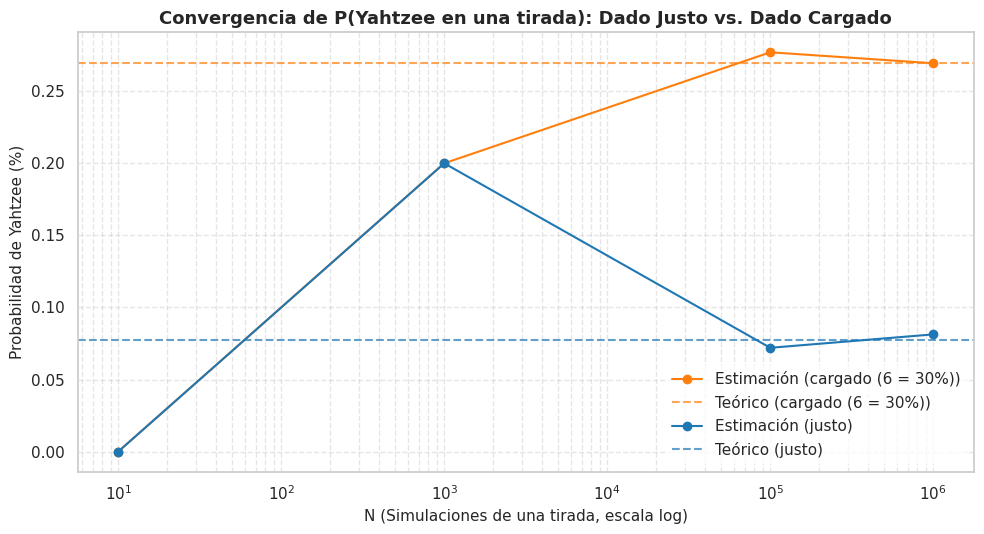

In [20]:
# Configuramos la figura
plt.figure(figsize=(10, 5.5))

# Diccionario de colores para distinguir dado justo vs cargado
colores = {
    "justo": "#1f77b4",            # Azul
    "cargado (6 = 30%)": "#ff7f0e"  # Naranja
}

# Filtramos datos para graficar de forma clara
for etiqueta, sub_df in df_c1.groupby("dado"):
    color_actual = colores.get(etiqueta, "gray")
    plt.plot(sub_df["N"], sub_df["estimado %"], marker="o", ls="-", ms=6, color=color_actual, label=f"Estimación ({etiqueta})")
    plt.axhline(sub_df["exacto %"].iloc[0], ls="--", alpha=0.7, color=color_actual, label=f"Teórico ({etiqueta})")

plt.xscale("log")
plt.xlabel("N (Simulaciones de una tirada, escala log)", fontsize=11)
plt.ylabel("Probabilidad de Yahtzee (%)", fontsize=11)
plt.title("Convergencia de P(Yahtzee en una tirada): Dado Justo vs. Dado Cargado", fontsize=13, fontweight="bold")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend(frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()

# Guardar y mostrar figura
plt.savefig("figuras/f2_convergencia_comparativa_yahtzee.png", dpi=150)
plt.show()

## 3.2.1 Efecto sobre las **combinaciones complejas** (una tirada)

**EXTRA:** Se mide, en **una tirada de cinco dados**
(sin estrategia, para aislar el efecto de la distribución), la frecuencia de cada combinación con dado justo y cargado,
de forma exacta (enumerando las 7.776 manos ponderadas por su probabilidad) y simulada (N = 100.000).
Las combinaciones se solapan: un Yahtzee cuenta también como «trío o más» y «póker o más»; el full house exige exactamente un trío y una pareja.

,combinación,justo exacto %,justo simulado %,cargado exacto %,cargado simulado %,factor (cargado/justo)
0,trío o más,21.296,21.222,27.308,27.216,x1.28
1,póker o más,2.006,1.999,3.931,3.863,x1.96
2,full house,3.858,3.938,4.956,4.971,x1.28
3,escalera corta,15.432,15.400,10.932,11.109,x0.71
4,escalera larga,3.086,3.122,2.028,2.081,x0.66
5,Yahtzee,0.077,0.076,0.270,0.249,x3.50


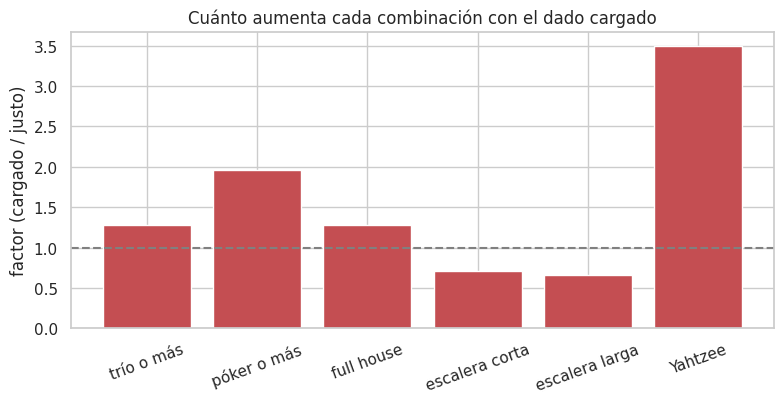

In [22]:
# 3.2.1 combinaciones complejas: justo vs Cargado
COMBINACIONES = ["trío o más", "póker o más", "full house", "escalera corta", "escalera larga", "Yahtzee"]

def clasificar_mano(dados: List[int]) -> Dict[str, bool]:
    """
    QUÉ HACE: indica qué combinaciones contiene una mano de 5 dados.
      cuentas = repeticiones ordenadas de mayor a menor, p. ej. [3, 2] = trío + pareja.
    MODIFICABLE: la definición de cada combinación.
    """
    cuentas = sorted(Counter(dados).values(), reverse=True)
    mayor = cuentas[0]
    return {"trío o más": mayor >= 3, "póker o más": mayor >= 4,
            "full house": cuentas == [3, 2],
            "escalera corta": has_sequence(dados, 4), "escalera larga": has_sequence(dados, 5),
            "Yahtzee": mayor == 5}

def combinaciones_exactas() -> Dict[str, float]:
    """Probabilidad exacta de cada combinación: suma de P(mano) sobre las 6^5 manos."""
    acum = {c: 0.0 for c in COMBINACIONES}
    for mano in itertools.product(CARAS, repeat=5):
        p = math.prod(PESOS[d - 1] for d in mano)
        for c, ok in clasificar_mano(list(mano)).items():
            if ok:
                acum[c] += p
    return acum

def combinaciones_simuladas(n: int) -> Dict[str, float]:
    """Frecuencia observada de cada combinación en n tiradas de 5 dados."""
    cont = Counter()
    for _ in range(n):
        mano = [roll_single_die() for _ in range(5)]
        for c, ok in clasificar_mano(mano).items():
            if ok:
                cont[c] += 1
    return {c: cont[c] / n for c in COMBINACIONES}

N_COMB = 100_000
random.seed(SEED)
res = {}
for etiqueta, p6 in [("justo", None), ("cargado", 0.30)]:
    with dado_temporal(p6):
        res[etiqueta] = (combinaciones_exactas(), combinaciones_simuladas(N_COMB))
filas = []
for c in COMBINACIONES:
    ej, sj = res["justo"][0][c], res["justo"][1][c]
    ec, sc_ = res["cargado"][0][c], res["cargado"][1][c]
    filas.append({"combinación": c, "justo exacto %": 100*ej, "justo simulado %": 100*sj,
                  "cargado exacto %": 100*ec, "cargado simulado %": 100*sc_, "factor (cargado/justo)": ec/ej})
df_comb = pd.DataFrame(filas)
df_comb.to_csv("resultados/f2_combinaciones.csv", index=False)
display(df_comb.style.format({"justo exacto %": "{:.3f}", "justo simulado %": "{:.3f}", "cargado exacto %": "{:.3f}",
                              "cargado simulado %": "{:.3f}", "factor (cargado/justo)": "x{:.2f}"}))
print()
plt.figure(figsize=(8, 4.2))
plt.bar(df_comb["combinación"], df_comb["factor (cargado/justo)"], color="#C44E52")
plt.axhline(1, color="gray", ls="--")
plt.ylabel("factor (cargado / justo)"); plt.xticks(rotation=20)
plt.title("Cuánto aumenta cada combinación con el dado cargado"); plt.tight_layout()
plt.savefig("figuras/f2_combinaciones.png", dpi=150); plt.show()

## 3.3 Efecto sobre el Yahtzee en **un turno** (3 tiradas)

La IA Montecarlo es lenta para miles de turnos, así que para esta medición se usa una **estrategia simple y
determinista**: «conserva la cara más repetida (en empate, la mayor) y relanza el resto». Con ella se puede
calcular además el **valor exacto** mediante una cadena de Markov sobre las 252 manos posibles, y comparar.

In [27]:
# Efecto sobre el Yahtzee en un turno
def _cara_a_conservar(dados: List[int]) -> int:
    """Cara más repetida; en empate de repeticiones, la de mayor valor."""
    return max(Counter(dados).items(), key=lambda kv: (kv[1], kv[0]))[0]

def simular_turno_voraz() -> bool:
    dados = [roll_single_die() for _ in range(5)]
    for _ in range(2):                                   # dos relanzamientos
        cara = _cara_a_conservar(dados)
        if dados.count(cara) == 5:
            break
        dados = [d if d == cara else roll_single_die() for d in dados]
    return len(set(dados)) == 1

def prob_exacta_yahtzee_turno_voraz() -> float:
    dist: Dict[tuple, float] = {}
    for mano in itertools.product(CARAS, repeat=5):               # 6^5 = 7.776 manos
        p = math.prod(PESOS[d - 1] for d in mano)
        clave = tuple(sorted(mano))
        dist[clave] = dist.get(clave, 0.0) + p
    for _ in range(2):
        nueva: Dict[tuple, float] = {}
        for mano, p in dist.items():
            cara = _cara_a_conservar(list(mano))
            k = mano.count(cara)
            if k == 5:
                nueva[mano] = nueva.get(mano, 0.0) + p
                continue
            for salida in itertools.product(CARAS, repeat=5 - k):
                q = math.prod(PESOS[d - 1] for d in salida)
                clave = tuple(sorted((cara,) * k + salida))
                nueva[clave] = nueva.get(clave, 0.0) + p * q
        dist = nueva
    return sum(p for mano, p in dist.items() if mano[0] == mano[-1])

def tabla_turno(ns=(10, 1_000, 100_000)) -> pd.DataFrame:
    filas = []
    for etiqueta, p6 in [("justo", None), ("cargado (6 = 30%)", 0.30)]:
        with dado_temporal(p6):
            exacto = prob_exacta_yahtzee_turno_voraz()
            for n in ns:
                est = sum(simular_turno_voraz() for _ in range(n)) / n
                filas.append({"dado": etiqueta, "N turnos": n, "estimado %": 100 * est, "exacto %": 100 * exacto})
    return pd.DataFrame(filas)

random.seed(SEED)
df_t = tabla_turno()
df_t.to_csv("resultados/f2_yahtzee_turno.csv", index=False)
display(df_t.style.format({"N turnos": "{:,.0f}", "estimado %": "{:.3f}", "exacto %": "{:.3f}"}))
ex_turno_j = df_t[(df_t["dado"] == "justo")]["exacto %"].iloc[0]
ex_turno_c = df_t[(df_t["dado"] != "justo")]["exacto %"].iloc[0]
print(f"Yahtzee en un turno → justo: {ex_turno_j:.2f} %   cargado: {ex_turno_c:.2f} %   factor x{ex_turno_c/ex_turno_j:.2f}")

,dado,N turnos,estimado %,exacto %
0,justo,10,0.000,4.603
1,justo,"1,000",5.200,4.603
2,justo,"100,000",4.549,4.603
3,cargado (6 = 30%),10,0.000,11.315
4,cargado (6 = 30%),"1,000",12.200,11.315
5,cargado (6 = 30%),"100,000",11.354,11.315


Yahtzee en un turno → justo: 4.60 %   cargado: 11.31 %   factor x2.46


## 3.4 Sensibilidad: ¿cuanto sesgo hace falta?(barrido de p(6))

,p(6),P(Yahtzee) en 1 tirada %,P(Yahtzee) en 1 turno %,factor tirada,factor turno
0,0.167,0.0772,4.603,x1.00,x1.00
1,0.200,0.0844,5.040,x1.09,x1.10
2,0.250,0.1356,7.137,x1.76,x1.55
3,0.300,0.2699,11.315,x3.50,x2.46
4,0.400,1.0364,26.170,x13.43,x5.69
5,0.500,3.1300,47.157,x40.56,x10.25


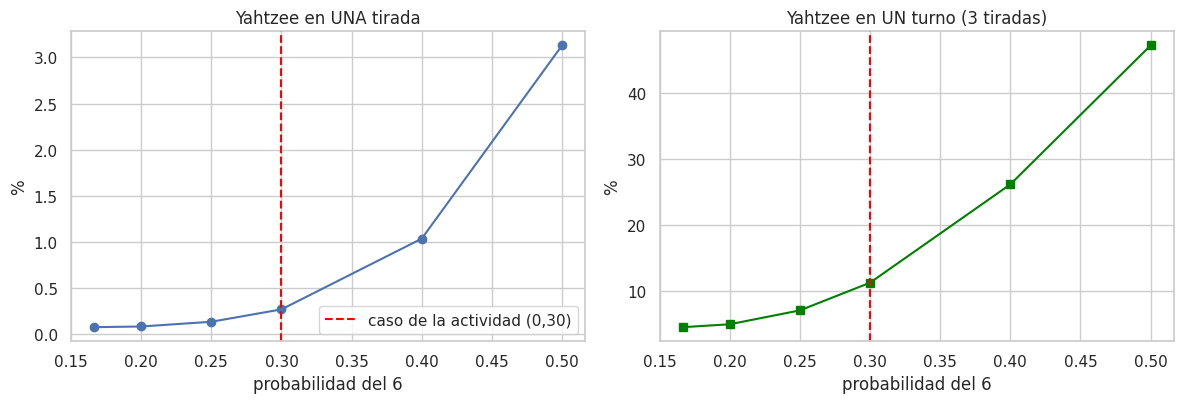

In [29]:
# 3.4 barrido de la probabilidad del 6
GRILLA_P6 = [1/6, 0.20, 0.25, 0.30, 0.40, 0.50]
filas = []
for p6 in GRILLA_P6:
    with dado_temporal(None if abs(p6 - 1/6) < 1e-12 else p6):
        filas.append({"p(6)": p6, "P(Yahtzee) en 1 tirada %": 100 * prob_yahtzee_una_tirada_exacta(),
                      "P(Yahtzee) en 1 turno %": 100 * prob_exacta_yahtzee_turno_voraz()})
df_b = pd.DataFrame(filas)
df_b["factor tirada"] = df_b["P(Yahtzee) en 1 tirada %"] / df_b["P(Yahtzee) en 1 tirada %"].iloc[0]
df_b["factor turno"] = df_b["P(Yahtzee) en 1 turno %"] / df_b["P(Yahtzee) en 1 turno %"].iloc[0]
df_b.to_csv("resultados/f2_barrido_p6.csv", index=False)
display(df_b.style.format({"p(6)": "{:.3f}", "P(Yahtzee) en 1 tirada %": "{:.4f}", "P(Yahtzee) en 1 turno %": "{:.3f}",
                           "factor tirada": "x{:.2f}", "factor turno": "x{:.2f}"}))
print()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(df_b["p(6)"], df_b["P(Yahtzee) en 1 tirada %"], "o-")
ax[0].axvline(0.30, color="red", ls="--", label="caso de la actividad (0,30)")
ax[0].set_xlabel("probabilidad del 6"); ax[0].set_ylabel("%"); ax[0].set_title("Yahtzee en UNA tirada"); ax[0].legend()
ax[1].plot(df_b["p(6)"], df_b["P(Yahtzee) en 1 turno %"], "s-", color="green")
ax[1].axvline(0.30, color="red", ls="--")
ax[1].set_xlabel("probabilidad del 6"); ax[1].set_ylabel("%"); ax[1].set_title("Yahtzee en UN turno (3 tiradas)")
plt.tight_layout(); plt.savefig("figuras/f2_barrido_p6.png", dpi=150); plt.show()

## 3.5 Distribucion de caras: justo vs cargado

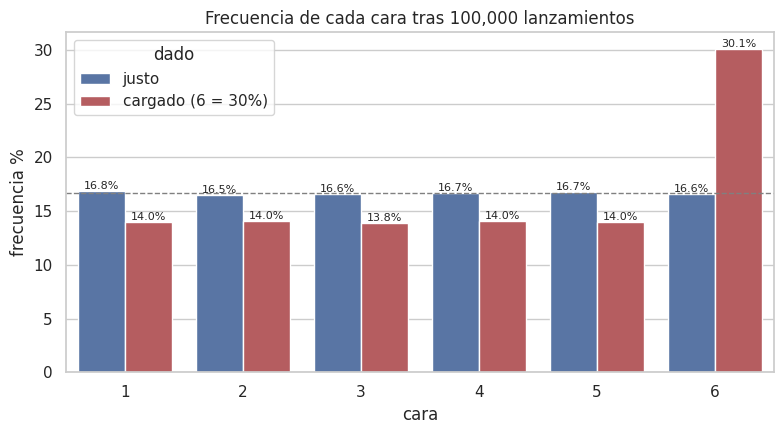

[0.16666666666666666,
 0.16666666666666666,
 0.16666666666666666,
 0.16666666666666666,
 0.16666666666666666,
 0.16666666666666666]

In [30]:
# 3.5 Distribucion de caras: justo vs cargado
random.seed(SEED)
N_HIST = 100_000
with dado_temporal(None):
    c_j = Counter(roll_single_die() for _ in range(N_HIST))
with dado_temporal(0.30):
    c_c = Counter(roll_single_die() for _ in range(N_HIST))
df_h = pd.DataFrame({"cara": CARAS * 2,
                     "frecuencia %": [100 * c_j[c] / N_HIST for c in CARAS] + [100 * c_c[c] / N_HIST for c in CARAS],
                     "dado": ["justo"] * 6 + ["cargado (6 = 30%)"] * 6})
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=df_h, x="cara", y="frecuencia %", hue="dado", palette=["#4C72B0", "#C44E52"])
ax.axhline(100 / 6, color="gray", ls="--", lw=1, label="1/6")
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)
plt.title(f"Frecuencia de cada cara tras {N_HIST:,} lanzamientos"); plt.tight_layout()
plt.savefig("figuras/f2_histograma_caras.png", dpi=150); plt.show()
df_h.to_csv("resultados/f2_histograma_caras.csv", index=False)
configurar_dado(None)   # deja el sistema en estado justo